In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from pathlib import Path

In [4]:
train_csv = Path("/content/train.csv")
val_csv = Path("/content/val.csv")
test_csv = Path("/content/test.csv")

movies_csv = Path("/content/movies.csv")

train = pd.read_csv(train_csv)
val = pd.read_csv(val_csv)
test = pd.read_csv(test_csv)
movies = pd.read_csv(movies_csv)

print(train.shape, "\n")
print(val.shape, "\n")
print(test.shape, "\n")

print(train.head(5), "\n")
print(val.head(5), "\n")
print(test.head(5), "\n")

(60419, 7) 

(7545, 7) 

(7545, 7) 

   uid   iid  userId  movieId  rating  like  timestamp
0    0   451       1     1210     5.0     1  964980499
1    0   722       1     2018     5.0     1  964980523
2    0   904       1     2628     4.0     0  964980523
3    0   961       1     2826     4.0     0  964980523
4    0  1143       1     3578     5.0     1  964980668 

   uid  iid  userId  movieId  rating  like  timestamp
0    0  360       1      954     5.0     1  964983219
1    0  449       1     1208     4.0     0  964983250
2    0  813       1     2329     5.0     1  964983263
3    0  992       1     2959     5.0     1  964983282
4    0  458       1     1219     2.0     0  964983393 

   uid   iid  userId  movieId  rating  like  timestamp
0    0   800       1     2291     5.0     1  964983664
1    0   500       1     1270     5.0     1  964983705
2    0   473       1     1240     5.0     1  964983723
3    0   447       1     1206     5.0     1  964983737
4    0  1168       1     3702 

In [5]:
import json

import torch
import torch.nn as nn

SEED = 42
K = 10
N_NEG = 4
BATCH = 1024
EPOCHS = 40
PATIENCE = 5
LR = 1e-3
WEIGHT_DECAY = 1e-5

D = Path("/content").expanduser()
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
np.random.seed(SEED)
torch.manual_seed(SEED)

meta = json.load(open(D / "meta.json"))
n_users, n_items = meta["n_users"], meta["n_items"]
val_neg, test_neg = np.load(D / "val_neg.npy"), np.load(D / "test_neg.npy")
print(device, n_users, n_items, val_neg.shape, test_neg.shape)

cuda 602 2097 (7545, 99) (7545, 99)


In [6]:
def sampled_metrics(S, df, neg, k=K):
    u = df["uid"].to_numpy()
    pos = S[u, df["iid"].to_numpy()]
    negs = S[u[:, None], neg]
    rank = (negs > pos[:, None]).sum(1) + 0.5 * (negs == pos[:, None]).sum(1)
    hit = (rank < k).astype(float)
    return hit.mean(), (hit / np.log2(rank + 2)).mean()


def full_metrics(S, hist, df, k=K):
    S = np.where(hist, -np.inf, S.astype(np.float64) + np.random.default_rng(SEED).random(S.shape) * 1e-9)
    top = np.argsort(-S, axis=1)[:, :k]
    rel = np.zeros((n_users, n_items), dtype=bool)
    rel[df["uid"].to_numpy(), df["iid"].to_numpy()] = True
    gains = np.take_along_axis(rel, top, 1)
    n_rel = rel.sum(1)
    m = n_rel > 0
    disc = 1 / np.log2(np.arange(2, k + 2))
    idcg = np.array([disc[:min(int(n), k)].sum() for n in n_rel])
    recall = (gains.sum(1)[m] / n_rel[m]).mean()
    ndcg = ((gains * disc).sum(1)[m] / idcg[m]).mean()
    return recall, ndcg, len(np.unique(top[m])) / n_items


def evaluate(S, hist, df, neg):
    hr, ndcg_s = sampled_metrics(S, df, neg)
    rec, ndcg, cov = full_metrics(S, hist, df)
    return {"HR@10_100": hr, "NDCG@10_100": ndcg_s, "Recall@10": rec, "NDCG@10": ndcg, "Coverage": cov}


def to_hist(*dfs):
    h = np.zeros((n_users, n_items), dtype=bool)
    for d in dfs:
        h[d["uid"].to_numpy(), d["iid"].to_numpy()] = True
    return h


hist_train = to_hist(train)
hist_trainval = to_hist(train, val)
hist_all = to_hist(train, val, test)

In [7]:
class NeuMF(nn.Module):
    def __init__(self, n_users, n_items, gmf_dim=32, mlp_dim=32, layers=(64, 32, 16), dropout=0.2):
        super().__init__()
        self.gmf_u = nn.Embedding(n_users, gmf_dim)
        self.gmf_i = nn.Embedding(n_items, gmf_dim)
        self.mlp_u = nn.Embedding(n_users, mlp_dim)
        self.mlp_i = nn.Embedding(n_items, mlp_dim)
        for e in (self.gmf_u, self.gmf_i, self.mlp_u, self.mlp_i):
            nn.init.normal_(e.weight, std=0.1)

        dims = [2 * mlp_dim, *layers]
        blocks = []
        for a, b in zip(dims[:-1], dims[1:]):
            blocks += [nn.Linear(a, b), nn.ReLU(), nn.Dropout(dropout)]
        self.mlp = nn.Sequential(*blocks)
        self.out = nn.Linear(gmf_dim + layers[-1], 1)

    def forward(self, u, i):
        g = self.gmf_u(u) * self.gmf_i(i)
        m = self.mlp(torch.cat([self.mlp_u(u), self.mlp_i(i)], dim=-1))
        return self.out(torch.cat([g, m], dim=-1)).squeeze(-1)


@torch.no_grad()
def score_all(model, chunk=64):
    model.eval()
    all_items = torch.arange(n_items, device=device)
    rows = []
    for s in range(0, n_users, chunk):
        us = torch.arange(s, min(s + chunk, n_users), device=device)
        uu = us[:, None].expand(-1, n_items).reshape(-1)
        ii = all_items[None, :].expand(len(us), -1).reshape(-1)
        rows.append(model(uu, ii).view(len(us), n_items).float().cpu())
    return torch.cat(rows).numpy()

In [8]:
tr_u, tr_i = train["uid"].to_numpy(), train["iid"].to_numpy()
pos_keys = np.unique(tr_u.astype(np.int64) * n_items + tr_i)
rng = np.random.default_rng(SEED)


def sample_negatives(n_neg):
    u = np.repeat(tr_u, n_neg)
    neg = rng.integers(0, n_items, len(u))
    while True:
        bad = np.isin(u.astype(np.int64) * n_items + neg, pos_keys)
        if not bad.any():
            return u, neg
        neg[bad] = rng.integers(0, n_items, bad.sum())

In [9]:
model = NeuMF(n_users, n_items).to(device)
opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
loss_fn = nn.BCEWithLogitsLoss()

log, best_ndcg, best_epoch, best_state, bad_epochs = [], -1.0, 0, None, 0

for epoch in range(1, EPOCHS + 1):
    model.train()
    nu, ni = sample_negatives(N_NEG)
    U = torch.from_numpy(np.concatenate([tr_u, nu])).long().to(device)
    I = torch.from_numpy(np.concatenate([tr_i, ni])).long().to(device)
    Y = torch.cat([torch.ones(len(tr_u)), torch.zeros(len(nu))]).to(device)
    perm = torch.randperm(len(U)).to(device)

    total = 0.0
    for s in range(0, len(U), BATCH):
        idx = perm[s:s + BATCH]
        opt.zero_grad()
        loss = loss_fn(model(U[idx], I[idx]), Y[idx])
        loss.backward()
        opt.step()
        total += loss.item() * len(idx)

    m = evaluate(score_all(model), hist_train, val, val_neg)
    log.append({"epoch": epoch, "loss": total / len(U), **m})
    print(f"{epoch:2d} | loss {total / len(U):.4f} | HR@10 {m['HR@10_100']:.4f} | "
          f"NDCG@10 {m['NDCG@10_100']:.4f} | full NDCG@10 {m['NDCG@10']:.4f}")

    if m["NDCG@10_100"] > best_ndcg:
        best_ndcg, best_epoch, bad_epochs = m["NDCG@10_100"], epoch, 0
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE:
            break

model.load_state_dict(best_state)
print(f"Лучшая эпоха: {best_epoch}, val NDCG@10 (100 кандидатов) = {best_ndcg:.4f}")

 1 | loss 0.4882 | HR@10 0.3184 | NDCG@10 0.1674 | full NDCG@10 0.0497
 2 | loss 0.4309 | HR@10 0.3211 | NDCG@10 0.1671 | full NDCG@10 0.0613
 3 | loss 0.4198 | HR@10 0.3476 | NDCG@10 0.1838 | full NDCG@10 0.0670
 4 | loss 0.3864 | HR@10 0.3787 | NDCG@10 0.2001 | full NDCG@10 0.0661
 5 | loss 0.3570 | HR@10 0.4142 | NDCG@10 0.2222 | full NDCG@10 0.0720
 6 | loss 0.3328 | HR@10 0.4388 | NDCG@10 0.2365 | full NDCG@10 0.0842
 7 | loss 0.3132 | HR@10 0.4502 | NDCG@10 0.2437 | full NDCG@10 0.0851
 8 | loss 0.2984 | HR@10 0.4582 | NDCG@10 0.2476 | full NDCG@10 0.0853
 9 | loss 0.2855 | HR@10 0.4631 | NDCG@10 0.2500 | full NDCG@10 0.0843
10 | loss 0.2739 | HR@10 0.4594 | NDCG@10 0.2496 | full NDCG@10 0.0860
11 | loss 0.2629 | HR@10 0.4648 | NDCG@10 0.2513 | full NDCG@10 0.0879
12 | loss 0.2536 | HR@10 0.4683 | NDCG@10 0.2514 | full NDCG@10 0.0844
13 | loss 0.2431 | HR@10 0.4681 | NDCG@10 0.2517 | full NDCG@10 0.0849
14 | loss 0.2331 | HR@10 0.4639 | NDCG@10 0.2483 | full NDCG@10 0.0855
15 | l

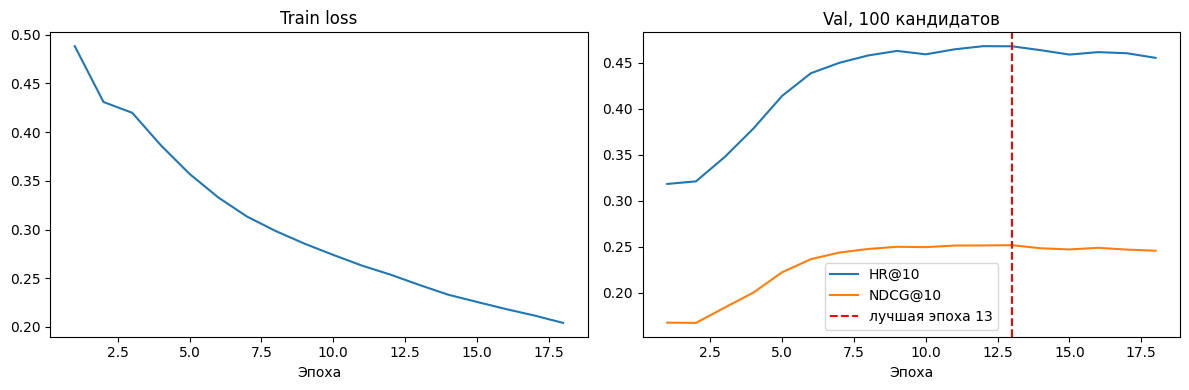

In [10]:
log_df = pd.DataFrame(log)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(log_df["epoch"], log_df["loss"])
ax[0].set(title="Train loss", xlabel="Эпоха")
ax[1].plot(log_df["epoch"], log_df["HR@10_100"], label="HR@10")
ax[1].plot(log_df["epoch"], log_df["NDCG@10_100"], label="NDCG@10")
ax[1].axvline(best_epoch, color="red", ls="--", label=f"лучшая эпоха {best_epoch}")
ax[1].set(title="Val, 100 кандидатов", xlabel="Эпоха")
ax[1].legend()
plt.tight_layout()
plt.show()

In [11]:
S_ncf = score_all(model)
S_pop = np.tile(hist_train.sum(0).astype(np.float64), (n_users, 1))

res = pd.DataFrame({
    "NCF val": evaluate(S_ncf, hist_train, val, val_neg),
    "Popularity val": evaluate(S_pop, hist_train, val, val_neg),
    "NCF test": evaluate(S_ncf, hist_trainval, test, test_neg),
    "Popularity test": evaluate(S_pop, hist_trainval, test, test_neg),
}).T.round(4)
res

,HR@10_100,NDCG@10_100,Recall@10,NDCG@10,Coverage
NCF val,0.4681,0.2517,0.0744,0.0849,0.3138
Popularity val,0.3229,0.1702,0.0510,0.0617,0.0410
NCF test,0.3915,0.2058,0.0589,0.0679,0.3214
Popularity test,0.2847,0.1451,0.0387,0.0513,0.0434


In [ ]:
import mlflow

mlflow.set_tracking_uri("http://localhost:5000")
mlflow.set_experiment("Сollaborative_Filtering")

METRICS = {
    "HR@10_100": f"hr_N_{K}_100cand",
    "NDCG@10_100": f"ndcg_N_{K}_100cand",
    "Recall@10": f"recall_N_{K}",
    "NDCG@10": f"ndcg_N_{K}",
    "Coverage": "coverage",
}

final = {
    "val": evaluate(S_ncf, hist_train, val, val_neg),
    "test": evaluate(S_ncf, hist_trainval, test, test_neg),
}
mlp_layers = [l.out_features for l in model.mlp if isinstance(l, nn.Linear)]

with mlflow.start_run(run_name="NCF_NeuMF"):
    mlflow.log_param("model_type", "NeuMF")
    mlflow.log_params({
        "top_k": K, "n_neg_train": N_NEG, "n_neg_eval": meta["n_neg_eval"],
        "batch_size": BATCH, "max_epochs": EPOCHS, "patience": PATIENCE,
        "lr": LR, "weight_decay": WEIGHT_DECAY, "seed": SEED,
        "gmf_dim": model.gmf_u.embedding_dim, "mlp_dim": model.mlp_u.embedding_dim,
        "mlp_layers": "-".join(map(str, mlp_layers)),
        "dropout": next(l.p for l in model.mlp if isinstance(l, nn.Dropout)),
        "n_params": sum(p.numel() for p in model.parameters()),
        "best_epoch": best_epoch, "epochs_run": len(log_df),
        "device": device, "test_fit_on": "train",
    })

    for _, r in log_df.iterrows():
        step = int(r["epoch"])
        mlflow.log_metric("curve_train_loss", float(r["loss"]), step=step)
        for col, key in METRICS.items():
            mlflow.log_metric(f"curve_val_{key}", float(r[col]), step=step)

    for split, m in final.items():
        for col, key in METRICS.items():
            mlflow.log_metric(f"{split}_{key}", float(m[col]))

    mlflow.log_figure(fig, "training_curves.png")
    mlflow.log_text(log_df.to_csv(index=False), "training_log.csv")

In [12]:
item_info = (pd.concat([train, val, test])[["iid", "movieId"]].drop_duplicates()
               .merge(movies[["movieId", "title", "genres"]], on="movieId")
               .set_index("iid").sort_index())
uid_of = dict(zip(train["userId"], train["uid"]))
all_df = pd.concat([train, val, test])


def recommend(user_id, n=10):
    u = uid_of[user_id]
    s = S_ncf[u].astype(np.float64).copy()
    s[hist_all[u]] = -np.inf
    top = np.argsort(-s)[:n]
    out = item_info.loc[top, ["title", "genres"]].copy()
    out["prob"] = 1 / (1 + np.exp(-s[top]))
    return out.reset_index()


def history(user_id, n=10):
    h = all_df[all_df["userId"] == user_id].sort_values("rating", ascending=False).head(n)
    return h.merge(item_info, left_on="iid", right_index=True)[["title", "genres", "rating"]]


demo_user = train["userId"].iloc[0]
print(history(demo_user).to_string(index=False), "\n")
print(recommend(demo_user).to_string(index=False))

                                            title                         genres  rating
Star Wars: Episode VI - Return of the Jedi (1983)        Action|Adventure|Sci-Fi     5.0
                                     Bambi (1942)       Animation|Children|Drama     5.0
                                 Gladiator (2000)         Action|Adventure|Drama     5.0
                           American Beauty (1999)                  Drama|Romance     5.0
                             Bottle Rocket (1996) Adventure|Comedy|Crime|Romance     5.0
                                 Tommy Boy (1995)                         Comedy     5.0
                             Billy Madison (1995)                         Comedy     5.0
                                 SLC Punk! (1998)                   Comedy|Drama     5.0
                            Grumpy Old Men (1993)                         Comedy     5.0
           Dumb & Dumber (Dumb and Dumber) (1994)               Adventure|Comedy     5.0 

 iid               

In [13]:
import time

N_TRIALS = 20
TUNE_EPOCHS = 30
TUNE_PATIENCE = 3
ES_METRIC = "NDCG@10_100"
TUNE_METRIC = "NDCG@10"

SPACE = {
    "gmf_dim": [8, 16, 32, 64],
    "mlp_dim": [8, 16, 32, 64],
    "layers": [(32, 16), (64, 32), (64, 32, 16), (128, 64, 32)],
    "dropout": [0.0, 0.2, 0.4],
    "weight_decay": [0.0, 1e-6, 1e-5, 1e-4, 1e-3],
    "lr": [5e-4, 1e-3, 3e-3],
    "n_neg": [2, 4, 8],
}
DEFAULT_CFG = {"gmf_dim": 32, "mlp_dim": 32, "layers": (64, 32, 16), "dropout": 0.2,
               "weight_decay": WEIGHT_DECAY, "lr": LR, "n_neg": N_NEG}


def sample_configs(n, seed=SEED):
    g = np.random.default_rng(seed)
    cfgs, seen = [DEFAULT_CFG], {tuple(DEFAULT_CFG.items())}
    while len(cfgs) < n:
        cfg = {k: v[g.integers(len(v))] for k, v in SPACE.items()}
        if tuple(cfg.items()) not in seen:
            seen.add(tuple(cfg.items()))
            cfgs.append(cfg)
    return cfgs


def sample_neg(n_neg, g):
    u = np.repeat(tr_u, n_neg)
    neg = g.integers(0, n_items, len(u))
    while True:
        bad = np.isin(u.astype(np.int64) * n_items + neg, pos_keys)
        if not bad.any():
            return u, neg
        neg[bad] = g.integers(0, n_items, bad.sum())


def train_trial(cfg, seed):
    torch.manual_seed(seed)
    g = np.random.default_rng(seed)
    m = NeuMF(n_users, n_items, cfg["gmf_dim"], cfg["mlp_dim"], cfg["layers"], cfg["dropout"]).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    loss_fn = nn.BCEWithLogitsLoss()
    best, bad_epochs = {"score": -1.0, "epoch": 0, "metrics": None, "state": None}, 0

    for epoch in range(1, TUNE_EPOCHS + 1):
        m.train()
        nu, ni = sample_neg(cfg["n_neg"], g)
        U = torch.from_numpy(np.concatenate([tr_u, nu])).long().to(device)
        I = torch.from_numpy(np.concatenate([tr_i, ni])).long().to(device)
        Y = torch.cat([torch.ones(len(tr_u)), torch.zeros(len(nu))]).to(device)
        perm = torch.randperm(len(U)).to(device)

        for s in range(0, len(U), BATCH):
            idx = perm[s:s + BATCH]
            opt.zero_grad()
            loss_fn(m(U[idx], I[idx]), Y[idx]).backward()
            opt.step()

        metrics = evaluate(score_all(m), hist_train, val, val_neg)
        if metrics[ES_METRIC] > best["score"]:
            best = {"score": metrics[ES_METRIC], "epoch": epoch, "metrics": metrics,
                    "state": {k: v.detach().cpu().clone() for k, v in m.state_dict().items()}}
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= TUNE_PATIENCE:
                break

    best["epochs_run"] = epoch
    return best

In [14]:
cfgs = sample_configs(N_TRIALS)
trials, tune_best_score, tune_best_state, best_cfg = [], -1.0, None, None

for t, cfg in enumerate(cfgs):
    t0 = time.time()
    r = train_trial(cfg, seed=SEED + t)
    row = {"trial": t, **cfg, "layers": "-".join(map(str, cfg["layers"])),
           "best_epoch": r["epoch"], "epochs_run": r["epochs_run"], **r["metrics"], "sec": round(time.time() - t0)}
    trials.append(row)

    if r["metrics"][TUNE_METRIC] > tune_best_score:
        tune_best_score, tune_best_state, best_cfg = r["metrics"][TUNE_METRIC], r["state"], cfg

    print(f"{t:2d} | {row['layers']:>9} g{cfg['gmf_dim']} m{cfg['mlp_dim']} do{cfg['dropout']} "
          f"wd{cfg['weight_decay']:g} lr{cfg['lr']:g} neg{cfg['n_neg']} | ep {r['epoch']:2d} | "
          f"{ES_METRIC} {r['metrics'][ES_METRIC]:.4f} | {TUNE_METRIC} {r['metrics'][TUNE_METRIC]:.4f} | {row['sec']}s")

tune_df = pd.DataFrame(trials).sort_values(TUNE_METRIC, ascending=False).reset_index(drop=True)
tune_df.round(4)

 0 |  64-32-16 g32 m32 do0.2 wd1e-05 lr0.001 neg4 | ep 13 | NDCG@10_100 0.2517 | NDCG@10 0.0849 | 16s
 1 |  64-32-16 g8 m64 do0.2 wd1e-05 lr0.003 neg2 | ep  7 | NDCG@10_100 0.2471 | NDCG@10 0.0791 | 9s
 2 |     32-16 g32 m8 do0.2 wd0.001 lr0.003 neg8 | ep  2 | NDCG@10_100 0.1674 | NDCG@10 0.0527 | 8s
 3 |  64-32-16 g32 m64 do0.0 wd0.001 lr0.001 neg4 | ep 12 | NDCG@10_100 0.1732 | NDCG@10 0.0586 | 14s
 4 | 128-64-32 g16 m8 do0.4 wd0.0001 lr0.001 neg8 | ep  2 | NDCG@10_100 0.1714 | NDCG@10 0.0592 | 8s
 5 |     64-32 g32 m16 do0.0 wd0 lr0.001 neg8 | ep  5 | NDCG@10_100 0.2437 | NDCG@10 0.0831 | 12s
 6 | 128-64-32 g8 m64 do0.0 wd0.0001 lr0.0005 neg8 | ep 17 | NDCG@10_100 0.2457 | NDCG@10 0.0879 | 32s
 7 |     32-16 g32 m16 do0.4 wd1e-05 lr0.003 neg8 | ep 17 | NDCG@10_100 0.2587 | NDCG@10 0.0871 | 30s
 8 |     32-16 g64 m64 do0.2 wd1e-05 lr0.001 neg2 | ep 11 | NDCG@10_100 0.2560 | NDCG@10 0.0880 | 11s
 9 |  64-32-16 g32 m8 do0.4 wd0.001 lr0.003 neg4 | ep  8 | NDCG@10_100 0.1726 | NDCG@10 0.

,trial,gmf_dim,mlp_dim,layers,dropout,weight_decay,lr,n_neg,best_epoch,epochs_run,HR@10_100,NDCG@10_100,Recall@10,NDCG@10,Coverage,sec
0,10,64,16,64-32,0.4,0.0000,0.0005,4,15,18,0.4641,0.2509,0.0781,0.0888,0.3095,16
1,14,64,64,64-32,0.4,0.0000,0.0005,8,9,12,0.4659,0.2529,0.0806,0.0882,0.2732,18
2,8,64,64,32-16,0.2,0.0000,0.0010,2,11,14,0.4702,0.2560,0.0734,0.0880,0.2389,11
3,6,8,64,128-64-32,0.0,0.0001,0.0005,8,17,20,0.4502,0.2457,0.0767,0.0879,0.2833,32
4,7,32,16,32-16,0.4,0.0000,0.0030,8,17,20,0.4725,0.2587,0.0785,0.0871,0.3004,30
5,13,32,32,32-16,0.0,0.0001,0.0030,4,20,23,0.4681,0.2520,0.0754,0.0860,0.2680,20
6,0,32,32,64-32-16,0.2,0.0000,0.0010,4,13,16,0.4681,0.2517,0.0744,0.0849,0.3138,16
7,16,64,64,64-32-16,0.2,0.0001,0.0005,8,21,24,0.4611,0.2485,0.0747,0.0835,0.2036,40
8,18,8,16,64-32-16,0.2,0.0000,0.0030,4,12,15,0.4689,0.2551,0.0746,0.0833,0.3386,15
9,5,32,16,64-32,0.0,0.0000,0.0010,8,5,8,0.4465,0.2437,0.0778,0.0831,0.2728,12


In [15]:
tuned_model = NeuMF(n_users, n_items, best_cfg["gmf_dim"], best_cfg["mlp_dim"],
                    best_cfg["layers"], best_cfg["dropout"]).to(device)
tuned_model.load_state_dict(tune_best_state)
S_tuned = score_all(tuned_model)
print("Лучшая конфигурация:", best_cfg)

res_tuned = pd.DataFrame({
    "NCF default val": evaluate(S_ncf, hist_train, val, val_neg),
    "NCF tuned val": evaluate(S_tuned, hist_train, val, val_neg),
    "NCF default test": evaluate(S_ncf, hist_trainval, test, test_neg),
    "NCF tuned test": evaluate(S_tuned, hist_trainval, test, test_neg),
}).T.round(4)
res_tuned

Лучшая конфигурация: {'gmf_dim': 64, 'mlp_dim': 16, 'layers': (64, 32), 'dropout': 0.4, 'weight_decay': 1e-06, 'lr': 0.0005, 'n_neg': 4}


,HR@10_100,NDCG@10_100,Recall@10,NDCG@10,Coverage
NCF default val,0.4681,0.2517,0.0744,0.0849,0.3138
NCF tuned val,0.4641,0.2509,0.0781,0.0888,0.3095
NCF default test,0.3915,0.2058,0.0589,0.0679,0.3214
NCF tuned test,0.3818,0.2009,0.0602,0.0695,0.3200
